# Math 465 Fall 2026

## Module 2. Demo 2: PCA of evolving data and high-dimensional images

Xiuyuan Cheng
xiuyuan.cheng@duke.edu


This notebook contains two PCA examples:

- moving-window PCA for evolving Hudson River measurements;
- high-dimensional PCA on 28 by 28 MNIST digit images.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.datasets import fetch_openml

### Example. PCA of moving windows

The local data contain daily medians of six surface measurements from January 1 through May 27, 2020: temperature, conductance, dissolved oxygen, pH, water elevation, and turbidity. The measurements come from [USGS station 01372043 near Poughkeepsie, New York](https://waterdata.usgs.gov/monitoring-location/USGS-01372043/).

We now ask a question: can a small number of common *window patterns* describe how the river evolves from winter into spring?


In [2]:
data = np.genfromtxt(
    'data/hudson_poughkeepsie_surface_daily_2020.csv',
    delimiter=',', names=True, dtype=None, encoding='utf-8'
)

dates_hudson = data['date'].astype('datetime64[D]')
features = [
    'temperature_C', 'conductance_uScm', 'oxygen_mgL',
    'pH', 'elevation_ft', 'turbidity_FNU'
]
X_hudson = np.column_stack([data[name] for name in features]).astype(float)

# Five variables have missing measurements on March 15 and 16.
# Interpolate these short gaps separately for each variable.
for j in range(X_hudson.shape[1]):
    good = np.isfinite(X_hudson[:, j])
    X_hudson[:, j] = np.interp(
        np.arange(len(X_hudson)), np.flatnonzero(good), X_hudson[good, j]
    )

# Use one common standardization for the entire record.
Z_hudson = (
    (X_hudson - X_hudson.mean(axis=0)) /
    X_hudson.std(axis=0, ddof=1)
)

print('number of days:', len(dates_hudson))
print('dimension at each day:', Z_hudson.shape[1])


number of days: 148
dimension at each day: 6


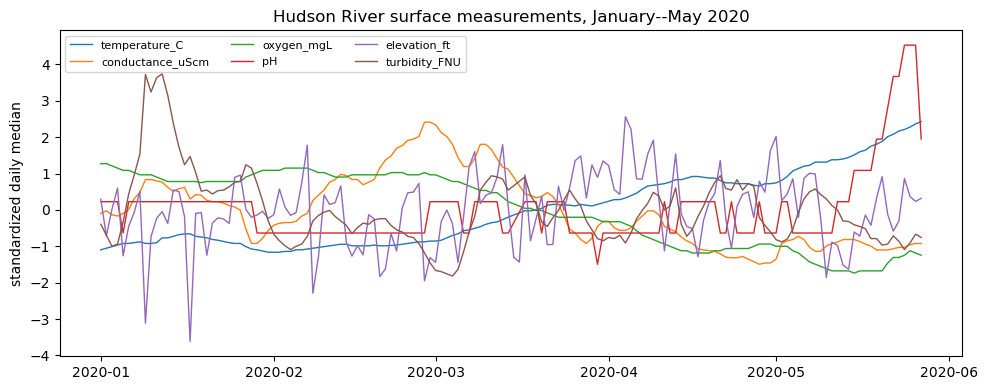

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for j, name in enumerate(features):
    ax.plot(dates_hudson, Z_hudson[:, j], linewidth=1, label=name)
ax.set(
    title='Hudson River surface measurements, January--May 2020',
    ylabel='standardized daily median'
)
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()


#### Construct the window data matrix

After standardization, the data matrix is

$$
Z=(z_{tj})\in\mathbb{R}^{148\times 6}.
$$

Rows are dates and columns are physical variables.

For window length $w$ and stride $s$, flatten each $w\times6$ window into one row of the PCA input matrix:

$$
\mathcal{W}_{i,:}=\operatorname{vec}(Z_i)^T,
\qquad
\mathcal{W}\in\mathbb{R}^{m\times6w}.
$$

Here $m=\left\lfloor(148-w)/s\right\rfloor+1$. Rows of $\mathcal{W}$ are windows, and columns are variable-by-day positions within a window. With $w=45$ and $s=1$, $\mathcal{W}\in\mathbb{R}^{104\times270}$. PCA treats the 104 windows as observations.


In [4]:
# Parameters for the moving-window construction
window_size = 45     # number of days in each window
stride = 1           # move forward this many days at a time

if not 2 <= window_size <= len(Z_hudson):
    raise ValueError('window_size must be between 2 and the number of days')
if stride < 1:
    raise ValueError('stride must be a positive integer')

starts = np.arange(0, len(Z_hudson) - window_size + 1, stride)
window_matrix = np.stack([
    Z_hudson[start:start + window_size].reshape(-1)
    for start in starts
])
window_indices = np.arange(1, len(starts) + 1)

window_pca = PCA()
# fit_transform learns the common patterns and returns the PCA coefficients.
window_scores = window_pca.fit_transform(window_matrix)
window_patterns = window_pca.components_.reshape(
    -1, window_size, len(features)
)

# Choose one global orientation for the first two shared PCs.
# Reversing a component and all its scores leaves the PCA unchanged.
oxygen_index = features.index('oxygen_mgL')
if window_patterns[0, :, oxygen_index].mean() < 0:
    window_pca.components_[0] *= -1
    window_scores[:, 0] *= -1

conductance_index = features.index('conductance_uScm')
half = window_size // 2
conductance_drop = (
    window_patterns[1, :half, conductance_index].mean()
    - window_patterns[1, -half:, conductance_index].mean()
)
if conductance_drop < 0:
    window_pca.components_[1] *= -1
    window_scores[:, 1] *= -1

print('window data matrix shape:', window_matrix.shape)
print('variance explained by PC1--PC5:',
      np.round(window_pca.explained_variance_ratio_[:5], 3))
print('variance explained by PC1--PC3:',
      np.round(window_pca.explained_variance_ratio_[:3].sum(), 3))


window data matrix shape: (104, 270)
variance explained by PC1--PC5: [0.428 0.129 0.073 0.04  0.037]
variance explained by PC1--PC3: 0.63


Each PC is now a complete 45-day, six-variable pattern—not merely a loading vector at one date. The next plot reshapes the first three PCs back into their temporal form.


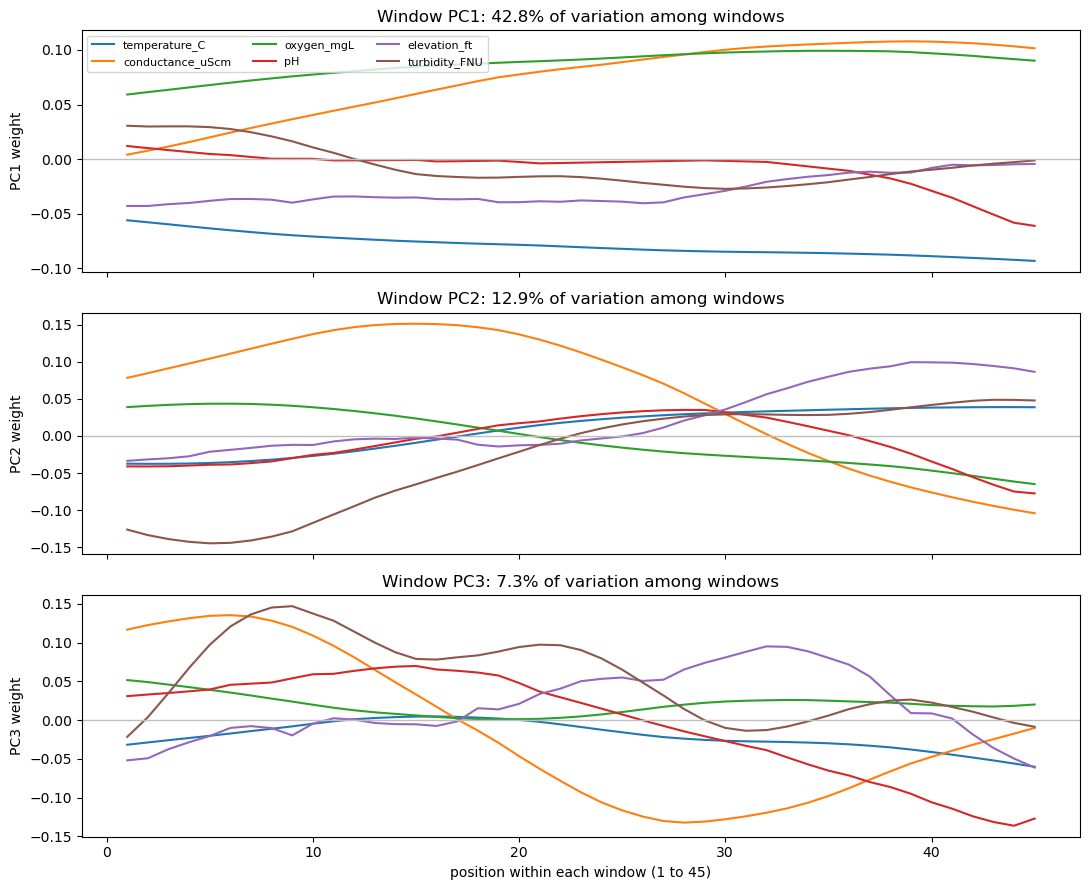

In [5]:
n_patterns = 3
position_in_window = np.arange(1, window_size + 1)
fig, axes = plt.subplots(n_patterns, 1, figsize=(11, 9), sharex=True)

for k, ax in enumerate(axes):
    for j, name in enumerate(features):
        ax.plot(position_in_window, window_patterns[k, :, j], label=name)
    ax.axhline(0, color='0.75', linewidth=1)
    ax.set_ylabel(f'PC{k + 1} weight')
    ax.set_title(
        f'Window PC{k + 1}: '
        f'{window_pca.explained_variance_ratio_[k]:.1%} of variation among windows'
    )

axes[-1].set_xlabel(f'position within each window (1 to {window_size})')
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout()


In [6]:
# How much of each PC is contributed by each physical variable?
for k in range(3):
    energy = (window_patterns[k] ** 2).sum(axis=0)
    energy = energy / energy.sum()
    print(f'PC{k + 1} variable contributions')
    for name, value in zip(features, energy):
        print(f'  {name:18s}: {value:5.1%}')


PC1 variable contributions
  temperature_C     : 28.2%
  conductance_uScm  : 29.3%
  oxygen_mgL        : 34.7%
  pH                :  1.5%
  elevation_ft      :  4.5%
  turbidity_FNU     :  1.7%
PC2 variable contributions
  temperature_C     :  4.0%
  conductance_uScm  : 48.2%
  oxygen_mgL        :  5.6%
  pH                :  5.0%
  elevation_ft      : 11.8%
  turbidity_FNU     : 25.4%
PC3 variable contributions
  temperature_C     :  3.2%
  conductance_uScm  : 40.4%
  oxygen_mgL        :  2.5%
  pH                : 19.5%
  elevation_ft      :  9.9%
  turbidity_FNU     : 24.5%


#### Project every window onto the common PCs

The pattern plots explain what each direction means. The coefficient plots below show when that pattern is present and with what sign. Because all windows use the same PCA basis, coefficients at different dates are directly comparable.


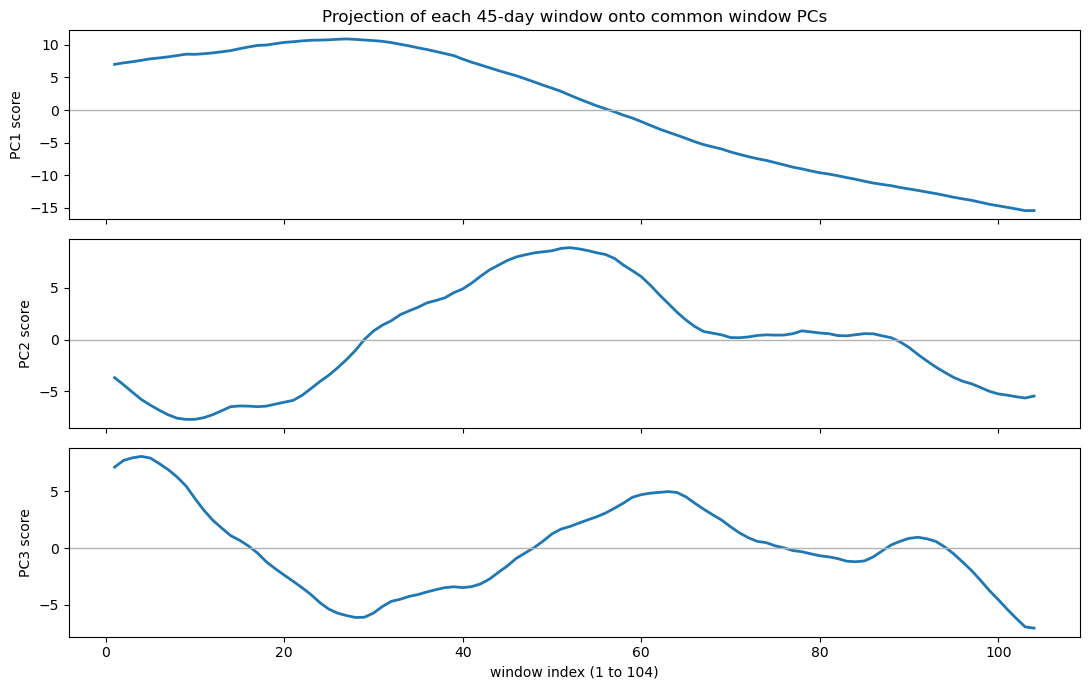

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(window_indices, window_scores[:, k], linewidth=2)
    ax.axhline(0, color='0.7', linewidth=1)
    ax.set_ylabel(f'PC{k + 1} score')
axes[0].set_title(
    f'Projection of each {window_size}-day window onto common window PCs'
)
axes[-1].set_xlabel(f'window index (1 to {len(window_indices)})')
plt.tight_layout()


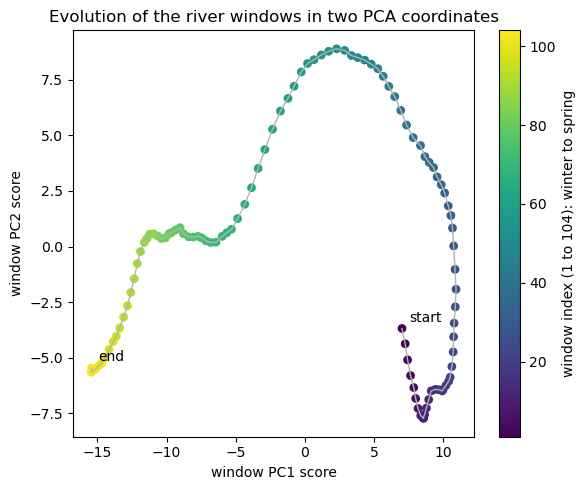

In [8]:
# A two-dimensional trajectory through the common window-PC coordinates
fig, ax = plt.subplots(figsize=(6, 5))
color = window_indices
points = ax.scatter(
    window_scores[:, 0], window_scores[:, 1],
    c=color, cmap='viridis', s=28
)
ax.plot(window_scores[:, 0], window_scores[:, 1], color='0.7', linewidth=1)
ax.annotate('start', window_scores[0, :2], xytext=(5, 5), textcoords='offset points')
ax.annotate('end', window_scores[-1, :2], xytext=(5, 5), textcoords='offset points')
ax.set(xlabel='window PC1 score', ylabel='window PC2 score',
       title='Evolution of the river windows in two PCA coordinates')
cbar = plt.colorbar(points, ax=ax)
cbar.set_label(f'window index (1 to {len(window_indices)}): winter to spring')
plt.tight_layout()


#### Interpretation for `window_size = 45`, `stride = 1`

- **PC1 — seasonal state:** Right corresponds to colder, oxygen-rich winter conditions; left corresponds to warmer, lower-oxygen spring conditions.
- **PC2 — transition pattern:** Its positive peak marks the strongest within-window change, led by decreasing conductance together with changes in turbidity and water elevation.

Therefore, the PC1–PC2 trajectory reads:

- **Bottom right:** stable winter state.
- **Moving upward:** the spring transition strengthens.
- **Near the top:** the transition is strongest.
- **Moving down and left:** the transition weakens as conditions become more spring-like.
- **Bottom left:** established spring state.

PC3 mixes shorter conductance, turbidity, pH, and elevation fluctuations. The smoothness of the trajectory is partly expected: neighboring stride-one windows share 44 of their 45 days.


### Example. PCA of image data

Here we load the MNIST data set.

In [9]:
from sklearn.datasets import fetch_openml

# Load data from https://www.openml.org/d/554
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='liac-arff')

In [10]:
X.shape

(70000, 784)

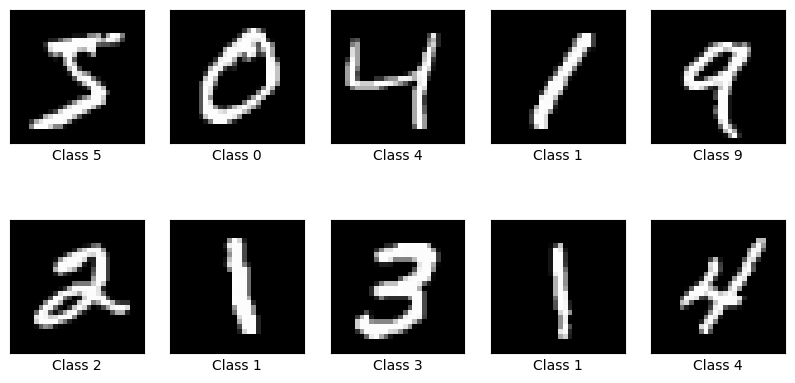

In [11]:
# visualize the first few data samples
plt.figure(figsize=(10, 5))
for i in range(10):
    l1_plot = plt.subplot(2, 5, i + 1)
    l1_plot.imshow(X[i,:].reshape(28, 28), cmap='gray')
    l1_plot.set_xticks(())
    l1_plot.set_yticks(())
    l1_plot.set_xlabel('Class %s' % y[i])

In [12]:
x2 = PCA(n_components=2, svd_solver='arpack').fit_transform(X);
x2.shape

(70000, 2)

Text(0.5, 1.0, 'MNIST in 2D')

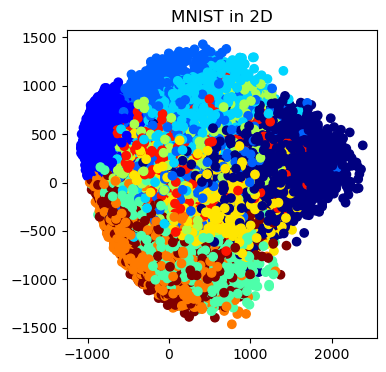

In [13]:
# plot the data colored by class labels
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.scatter(x2[:, 0], x2[:, 1], c=np.float32(y), cmap='jet')
ax.set_title("MNIST in 2D")

A two-dimensional PCA representation does not clearly separate all ten digits.

We can also reshape the PCA loading vectors as images to visualize directions of pixel variation.

In [14]:
# visualize the first 10 PCs as 28 by 28 images
output = PCA(n_components=100, svd_solver='arpack').fit(X);
pcXs = output.components_


In [15]:
pcXs.shape

(100, 784)

Text(0.5, 1.0, 'First 100 singular values')

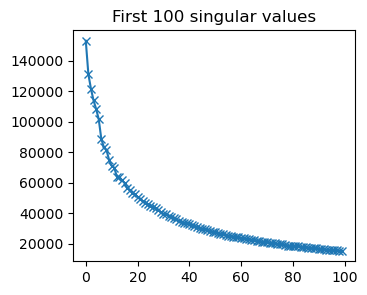

In [16]:
plt.figure(figsize=(8, 3))
plt.subplot(1,2,1)
plt.plot(output.singular_values_, marker='x' ); 
plt.title('First 100 singular values')

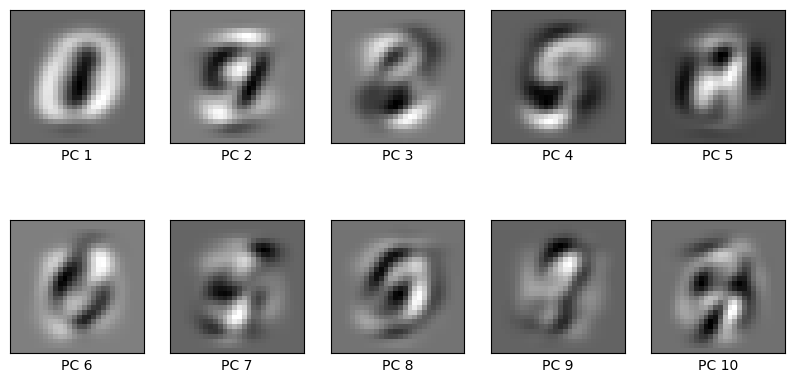

In [17]:
fig=plt.figure(figsize=(10, 5))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    im = ax.imshow(pcXs[i,:].reshape(28, 28), cmap='gray')
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_xlabel('PC %i' % (i + 1))
plt.show()

In [18]:
# select two classes
labels = np.float32(y);

X_sub = X[labels < 2, :];
y_sub  = labels[labels < 2];

n1 = np.shape(X_sub)[0]
n2 = 2000

rng=np.random.RandomState(202103)
idx = rng.permutation(n1)[0:n2]
idx[:5]
#idx=np.random.permutation(n1)[0:n2]



array([11066,  1100, 13510,  5983, 14117])

In [19]:
# subsample to make the dataset smaller
X_sub = X_sub[idx,: ]
y_sub = y_sub[idx]

X_sub.shape

(2000, 784)

In [20]:
y_sub[:20]

array([0., 1., 0., 1., 1., 1., 1., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0.,
       1., 0., 1.], dtype=float32)

In [21]:
x2 = PCA(n_components=2, svd_solver='arpack').fit_transform(X_sub);
x2.shape

(2000, 2)

In [22]:
pcXs = PCA(n_components=2, svd_solver='arpack').fit(X_sub).components_
pcXs.shape

(2, 784)

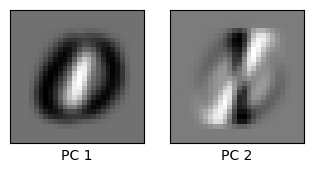

In [23]:
fig=plt.figure(figsize=(10, 5))
for i in range(2):
    ax = plt.subplot(2, 5, i + 1)
    im = ax.imshow(pcXs[i,:].reshape(28, 28), cmap='gray')
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_xlabel('PC %i' % (i + 1))
plt.show()

Text(0.5, 1.0, 'Subsampled MNIST data in 2D')

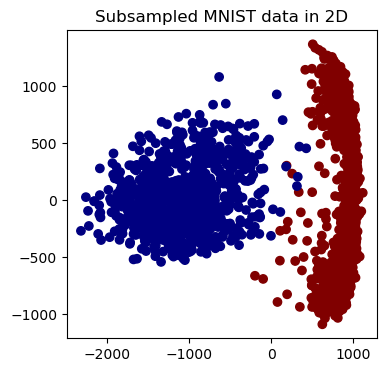

In [24]:
# plot the data colored by class labels
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.scatter(x2[:, 0], x2[:, 1], c= y_sub, cmap='jet')
ax.set_title("Subsampled MNIST data in 2D")

In [25]:
y_sub

array([0., 1., 0., ..., 0., 1., 0.], shape=(2000,), dtype=float32)

### Discussion

- Why is a two-dimensional PCA representation insufficient for all ten digits?
- What do the leading principal-component images represent?
- How does the singular-value decay inform a possible dimension choice?
- Why does restricting attention to two digit classes change what is visible in the score plot?